<a href="https://colab.research.google.com/github/unknxwNS/Ihopeitworks/blob/main/%D0%9B%D0%A05_%D0%9C%D1%96%D1%85%D0%B0%D0%BB%D1%8C%D0%BE%D0%B2_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")


In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Path to dataset files: /kaggle/input/daily-climate-time-series-data-delhi-india


In [ ]:

import pandas as pd
import os
import glob

csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
df = pd.read_csv(csv_files[0])

print("Розмір датасету:", df.shape)
print("\nПерші 5 рядків:")
display(df.head())

print("\nІнформація про датасет:")
df.info()

print("\nОписова статистика:")
display(df.describe(include="all"))


Розмір датасету: (3557, 29)

Перші 5 рядків:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622


Підготовка даних

In [ ]:

# Перетворення DATE у формат datetime
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

# Видалення рядків без дати
df = df.dropna(subset=["DATE"])

# Сортування за датою
df = df.sort_values("DATE")

# Видалення зайвих колонок
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

# Встановлення DATE як індексу
df = df.set_index("DATE")

# Перегляд результату
display(df.head())


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [ ]:

print("Розмір датасету:", df.shape)
print("\nТипи даних:")
print(df.dtypes)

print("\nІнформація про датасет:")
df.info()

print("\nСтатистичні характеристики:")
display(df.describe())


Розмір датасету: (3557, 27)

Типи даних:
tempmax                  float64
tempmin                  float64
temp                     float64
feelslikemax             float64
feelslikemin             float64
feelslike                float64
humidity                 float64
precip                   float64
precipprob                 int64
precipcover              float64
windspeed                float64
sealevelpressure         float64
conditions                object
Year                       int64
month                      int64
dayofweek                  int64
dayofyear                  int64
year-2000                  int64
weekofyear                 int64
tempmax_humidity         float64
tempmin_humidity         float64
temp_humidity            float64
feelslikemax_humidity    float64
feelslikemin_humidity    float64
feelslike_humidity       float64
temp_range               float64
heat_index               float64
dtype: object

Інформація про датасет:
<class 'pandas.core.frame.Dat

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,1.783095,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,4.009455,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,45.830000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


In [ ]:

# Кількість пропущених значень у кожній колонці
print("Пропущені значення:")
print(df.isnull().sum())

# Загальна кількість пропущених значень
print("\nУсього пропущених значень:", df.isnull().sum().sum())


Пропущені значення:
tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
conditions               0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64

Усього пропущених значень: 0


Графік температури

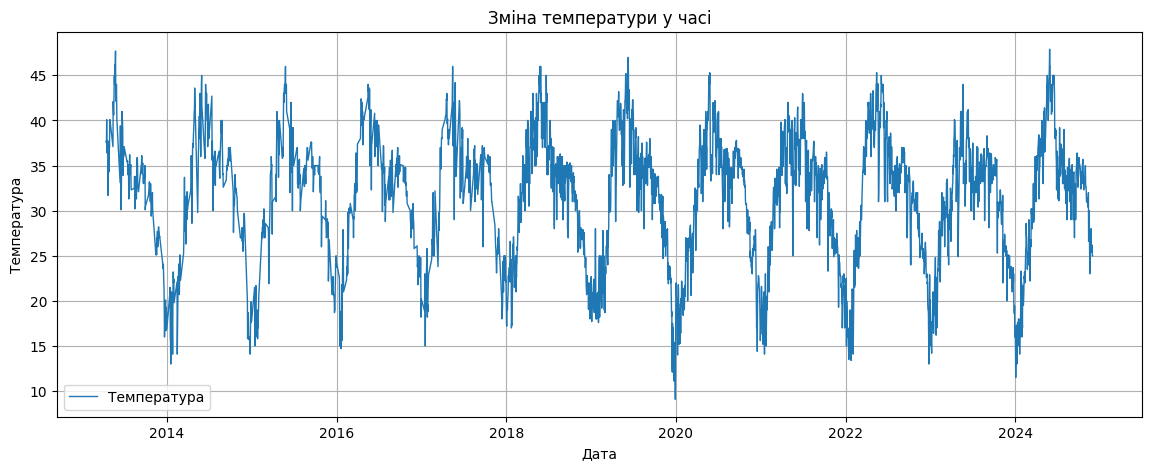

In [ ]:

# Побудова графіка зміни температури у часі
temp_col = next(c for c in df.columns if "temp" in c.lower())

plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], label="Температура", linewidth=1)
plt.title("Зміна температури у часі")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


Ковзне середнє

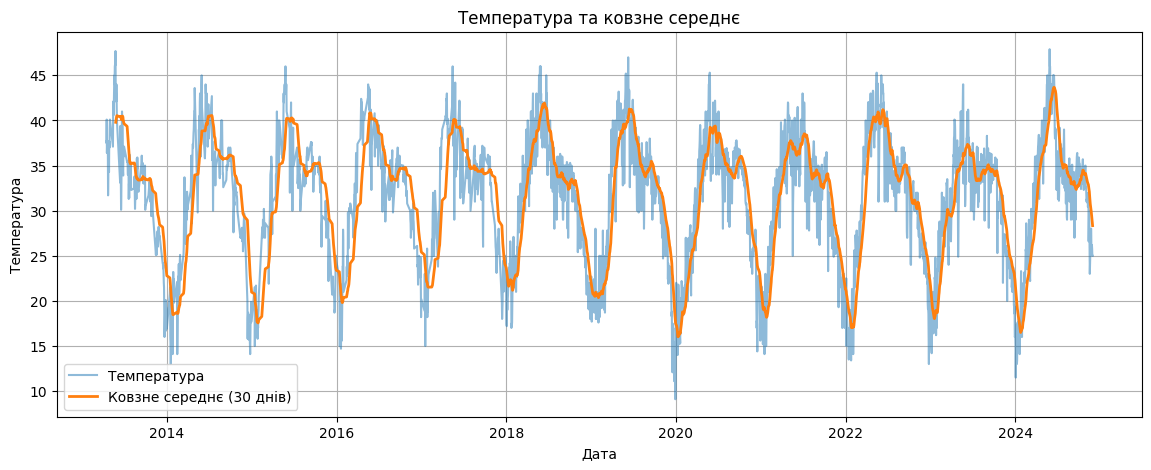

In [ ]:

# Обчислення та візуалізація ковзного середнього температури
df["Rolling_Mean"] = df[temp_col].rolling(window=30).mean()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], label="Температура", alpha=0.5)
plt.plot(df.index, df["Rolling_Mean"], label="Ковзне середнє (30 днів)", linewidth=2)
plt.title("Температура та ковзне середнє")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


Розподіл температури

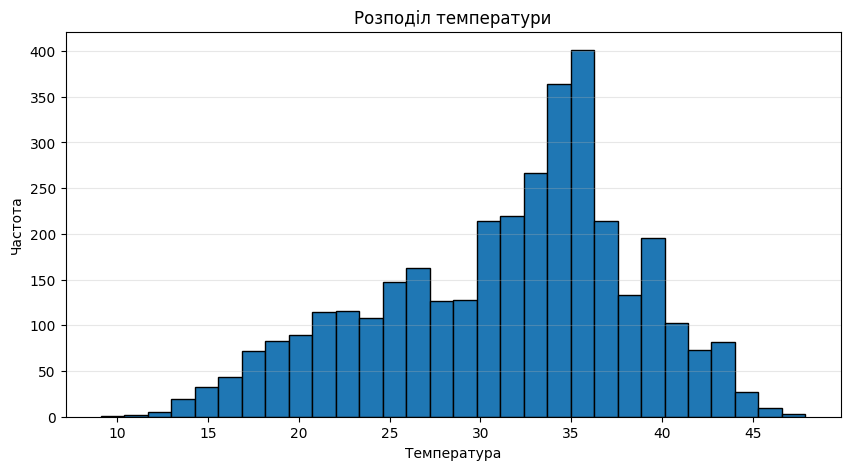

In [ ]:

plt.figure(figsize=(10, 5))
plt.hist(df[temp_col].dropna(), bins=30, edgecolor="black")
plt.title("Розподіл температури")
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.grid(axis="y", alpha=0.3)
plt.show()


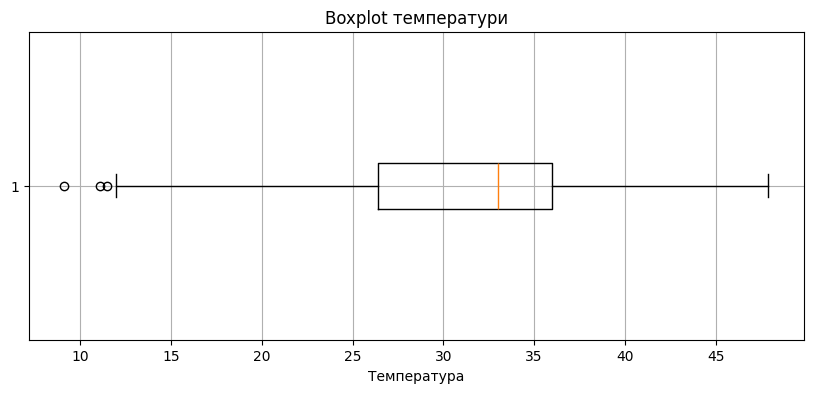

In [ ]:

plt.figure(figsize=(10, 4))
plt.boxplot(df[temp_col].dropna(), vert=False)
plt.title("Boxplot температури")
plt.xlabel("Температура")
plt.grid(True)
plt.show()


Аналіз автокореляції
ACF

PACF

<Figure size 1200x500 with 0 Axes>

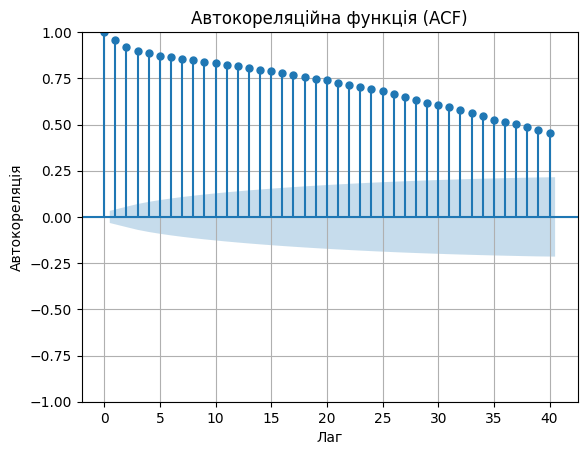

In [ ]:

from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))
plot_acf(df[temp_col].dropna(), lags=40)
plt.title("Автокореляційна функція (ACF)")
plt.xlabel("Лаг")
plt.ylabel("Автокореляція")
plt.grid(True)
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

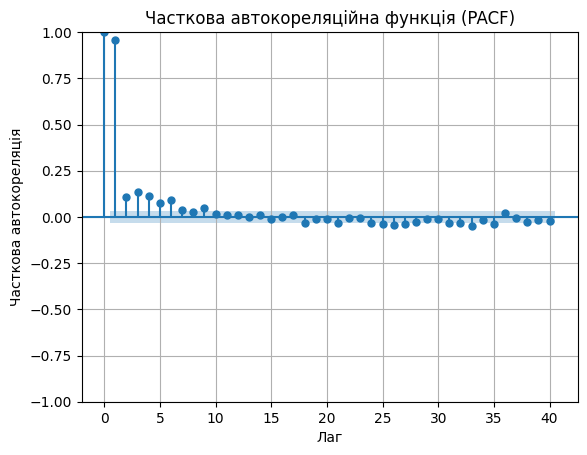

In [ ]:

from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(df[temp_col].dropna(), lags=40, method="ywm")
plt.title("Часткова автокореляційна функція (PACF)")
plt.xlabel("Лаг")
plt.ylabel("Часткова автокореляція")
plt.grid(True)
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

Кількість значень train: 2845
Кількість значень test: 712
Остання дата train: 2022-12-19 00:00:00
Перша дата test: 2022-12-20 00:00:00


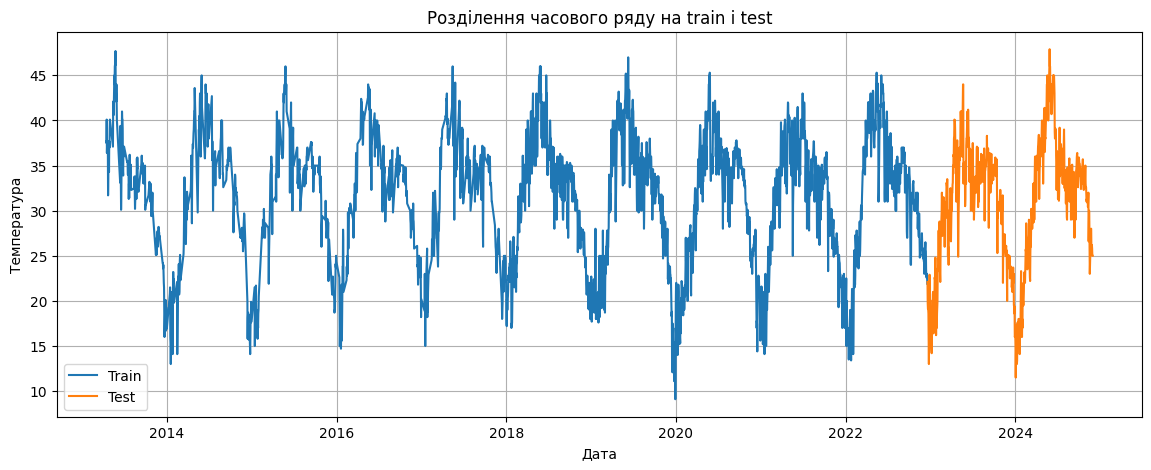

In [ ]:

# Цільовий часовий ряд температури
ts = df[temp_col].copy()

# Обробка пропущених значень
ts = ts.interpolate(method="time").ffill().bfill()

# Розділення у часовому порядку: 80% — train, 20% — test
split_idx = int(len(ts) * 0.8)

train = ts.iloc[:split_idx]
test = ts.iloc[split_idx:]

print("Кількість значень train:", len(train))
print("Кількість значень test:", len(test))
print("Остання дата train:", train.index[-1])
print("Перша дата test:", test.index[0])

# Візуалізація розділення
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test")
plt.title("Розділення часового ряду на train і test")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

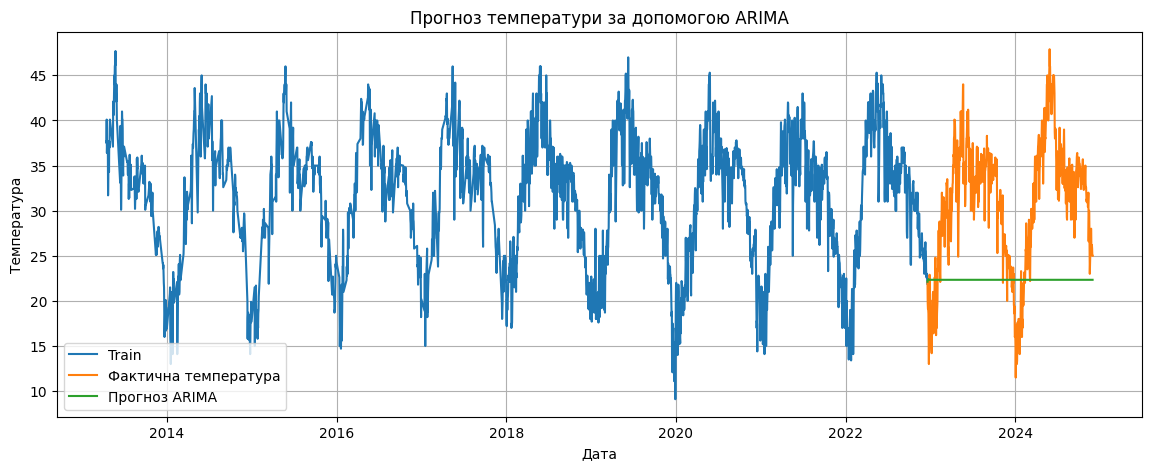

In [ ]:

from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import matplotlib.pyplot as plt

# Використовуємо числовий індекс для навчання ARIMA
train_values = train.astype(float).reset_index(drop=True)
test_values = test.astype(float).reset_index(drop=True)

# Навчання моделі
model_arima = ARIMA(train_values, order=(5, 1, 0))
arima_fit = model_arima.fit()

# Прогноз для тестової вибірки
forecast_values = arima_fit.forecast(steps=len(test_values))

# Повертаємо дати тестової вибірки
arima_pred = pd.Series(
    forecast_values.to_numpy(),
    index=test.index,
    name="ARIMA"
)

# Побудова графіка
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Train")
plt.plot(test.index, test.values, label="Фактична температура")
plt.plot(arima_pred.index, arima_pred.values, label="Прогноз ARIMA")
plt.title("Прогноз температури за допомогою ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 2845
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -6111.368
Date:                Tue, 13 Oct 2026   AIC                          12234.737
Time:                        09:34:14   BIC                          12270.455
Sample:                             0   HQIC                         12247.620
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1820      0.015    -11.899      0.000      -0.212      -0.152
ar.L2         -0.2020      0.018    -11.155      0.000      -0.237      -0.166
ar.L3         -0.1587      0.019     -8.177      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

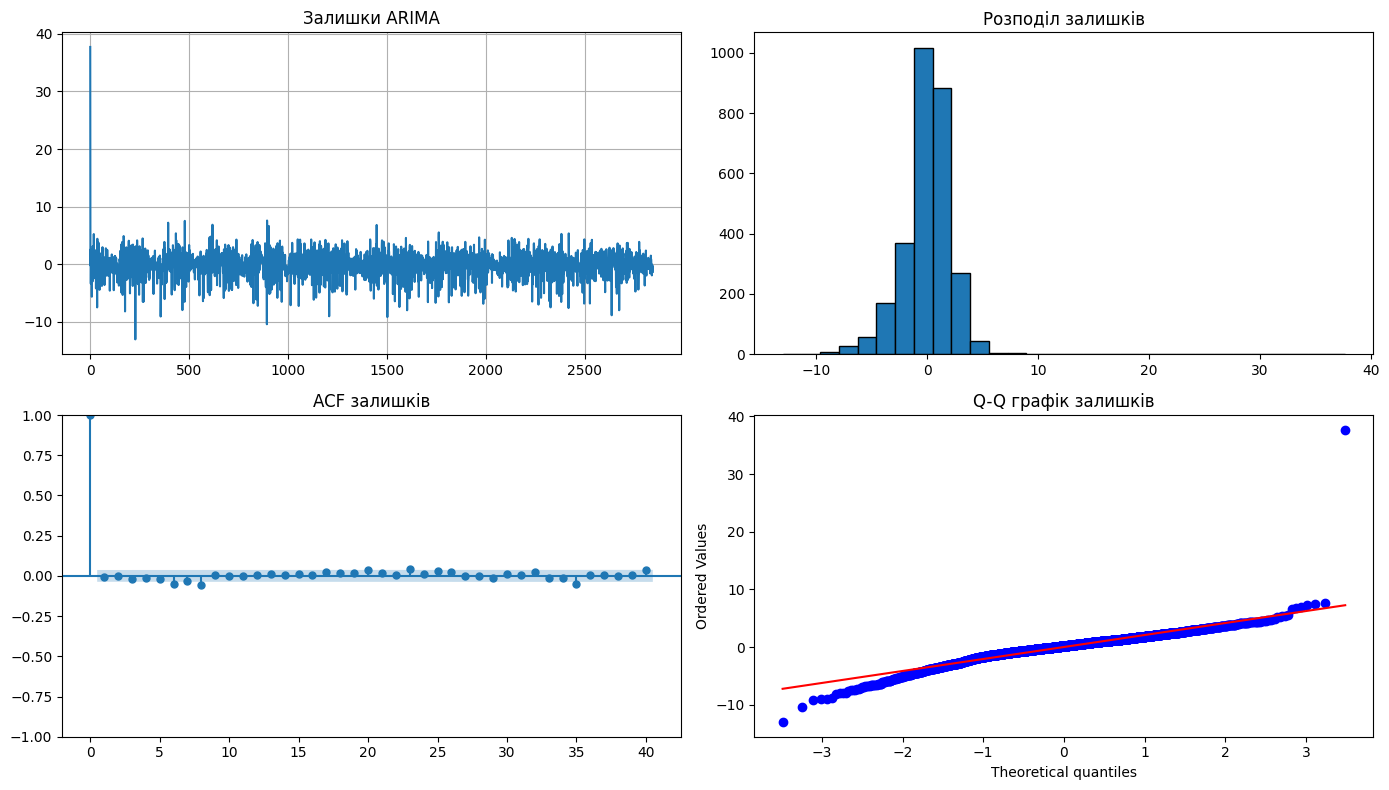

In [ ]:

# Аналіз залишків моделі ARIMA
residuals = arima_fit.resid

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(residuals)
axes[0, 0].set_title("Залишки ARIMA")
axes[0, 0].grid(True)

axes[0, 1].hist(residuals, bins=30, edgecolor="black")
axes[0, 1].set_title("Розподіл залишків")

from statsmodels.graphics.tsaplots import plot_acf
plot_acf(residuals, lags=40, ax=axes[1, 0])
axes[1, 0].set_title("ACF залишків")

from scipy.stats import probplot
probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q графік залишків")

plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_true = np.asarray(test, dtype=float)
y_pred = np.asarray(arima_pred, dtype=float)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# MAPE обчислюємо лише для ненульових фактичних значень
mask = np.abs(y_true) > 1e-8
mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")


MAE:  9.7498
RMSE: 11.1253
MAPE: 29.69%


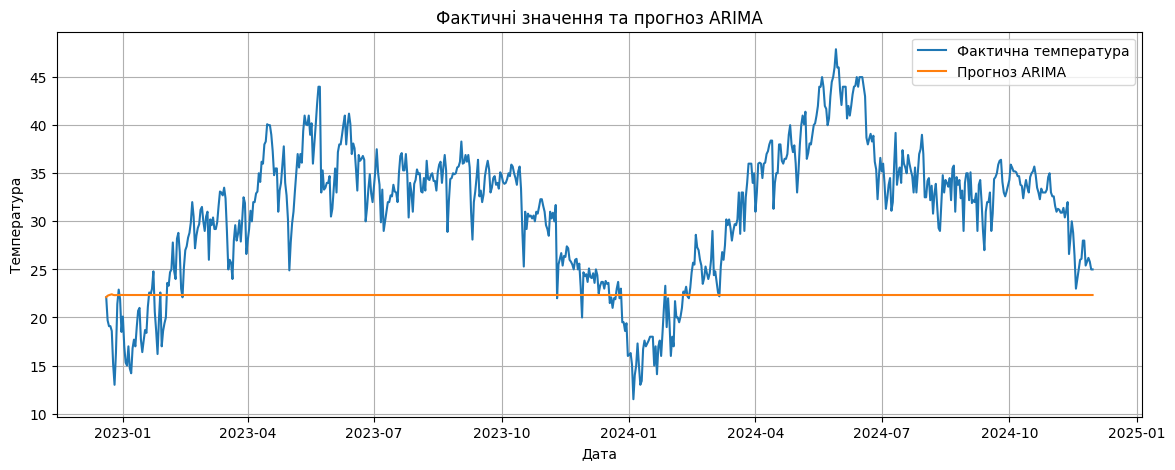

In [ ]:

plt.figure(figsize=(14, 5))

plt.plot(test.index, test.values, label="Фактична температура")
plt.plot(arima_pred.index, arima_pred.values, label="Прогноз ARIMA")

plt.title("Фактичні значення та прогноз ARIMA")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [ ]:

%pip install prophet -q

from prophet import Prophet

# Prophet потребує колонки ds (дата) та y (значення)
prophet_train = pd.DataFrame({
    "ds": train.index,
    "y": train.values
})

prophet_test = pd.DataFrame({
    "ds": test.index,
    "y": test.values
})

display(prophet_train.head())


,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


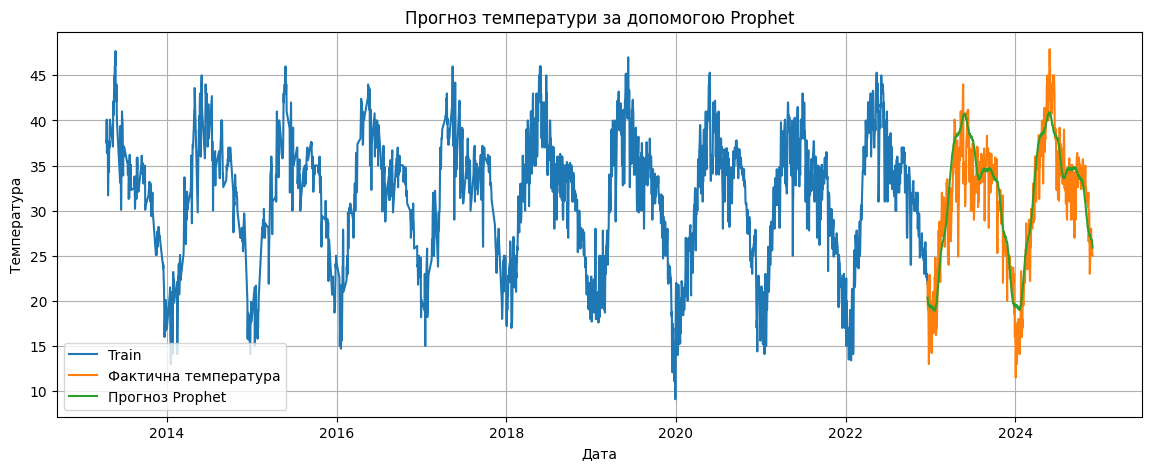

In [ ]:

# Створення та навчання моделі
model_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

model_prophet.fit(prophet_train)

# Прогноз на період тестової вибірки
prophet_forecast = model_prophet.predict(prophet_test[["ds"]])

prophet_pred = pd.Series(
    prophet_forecast["yhat"].values,
    index=test.index,
    name="Prophet"
)

# Візуалізація прогнозу
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Train")
plt.plot(test.index, test.values, label="Фактична температура")
plt.plot(prophet_pred.index, prophet_pred.values, label="Прогноз Prophet")
plt.title("Прогноз температури за допомогою Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


Прогноз

In [ ]:
# Побудуйте прогноз Prophet для тестового періоду

# Прогноз на тестовий період
prophet_forecast = model_prophet.predict(
    pd.DataFrame({"ds": test.index})
)

prophet_pred = pd.Series(
    prophet_forecast["yhat"].values,
    index=test.index,
    name="Prophet"
)

display(prophet_forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())


,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,20.362883,16.741868,23.887927
1,2022-12-21,20.154605,16.938923,23.536927
2,2022-12-22,19.937714,16.449963,23.498224
3,2022-12-23,19.750789,16.129003,23.375620
4,2022-12-24,19.541161,16.315718,22.853201


In [ ]:
# Обчисліть MAE, RMSE, MAPE для Prophet

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_true = np.asarray(test, dtype=float)
y_pred = np.asarray(prophet_pred, dtype=float)

mae_prophet = mean_absolute_error(y_true, y_pred)
rmse_prophet = np.sqrt(mean_squared_error(y_true, y_pred))

mask = np.abs(y_true) > 1e-8
mape_prophet = np.mean(
    np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
) * 100

print(f"MAE:  {mae_prophet:.4f}")
print(f"RMSE: {rmse_prophet:.4f}")
print(f"MAPE: {mape_prophet:.2f}%")


MAE:  2.3378
RMSE: 3.0343
MAPE: 8.28%


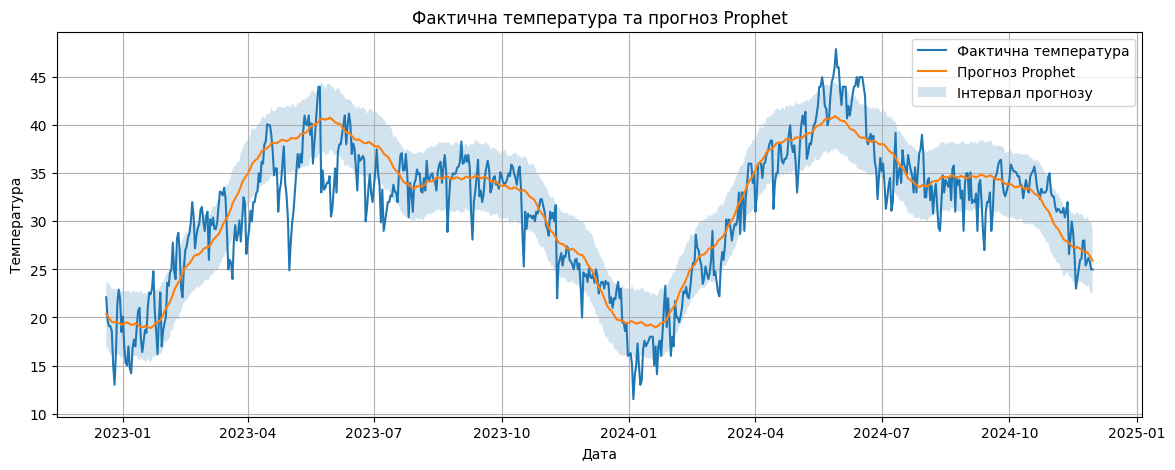

In [ ]:
# Візуалізуйте фактичні значення та прогноз Prophet

plt.figure(figsize=(14, 5))

plt.plot(test.index, test.values, label="Фактична температура")
plt.plot(prophet_pred.index, prophet_pred.values, label="Прогноз Prophet")

plt.fill_between(
    test.index,
    prophet_forecast["yhat_lower"],
    prophet_forecast["yhat_upper"],
    alpha=0.2,
    label="Інтервал прогнозу"
)

plt.title("Фактична температура та прогноз Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


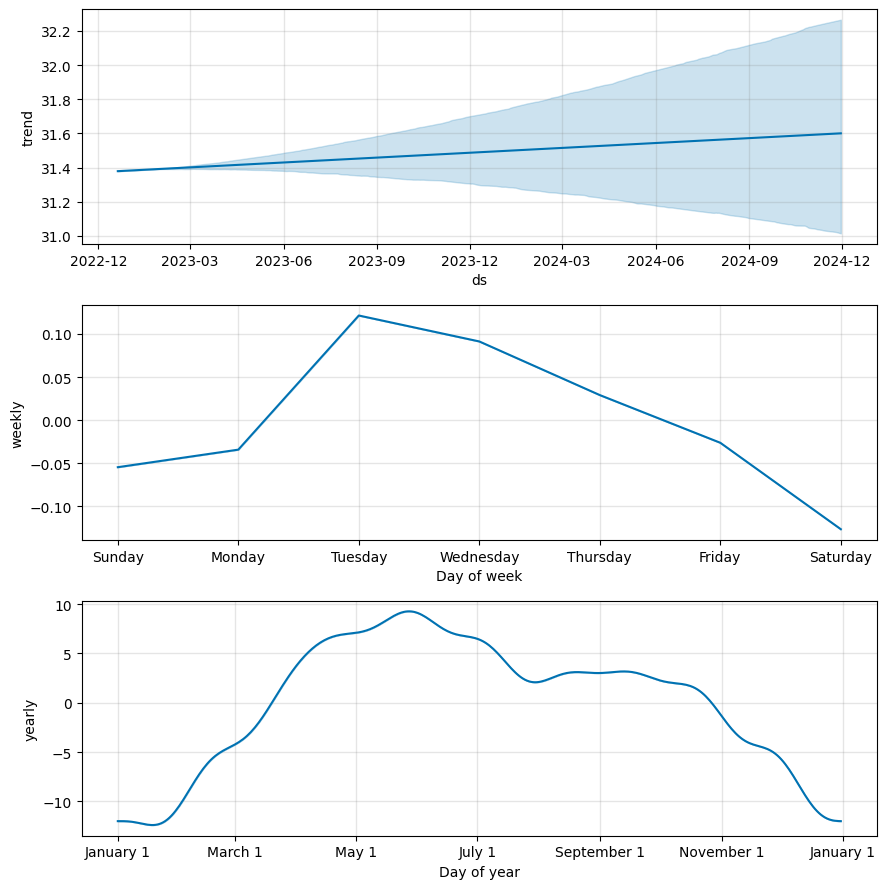

In [ ]:
# Побудуйте компоненти моделі Prophet

# Компоненти тренду та сезонності
fig = model_prophet.plot_components(prophet_forecast)
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [ ]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM

%pip install tensorflow -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# Масштабування даних
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train.to_numpy().reshape(-1, 1))

# Довжина вхідної послідовності
window = 30

X_train, y_train = [], []

for i in range(window, len(train_scaled)):
    X_train.append(train_scaled[i-window:i, 0])
    y_train.append(train_scaled[i, 0])

X_train = np.array(X_train).reshape(-1, window, 1)
y_train = np.array(y_train)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)


X_train: (2815, 30, 1)
y_train: (2815,)


In [ ]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування

# Останні 10% тренувальних послідовностей використаємо для валідації
val_size = max(1, int(len(X_train) * 0.1))

X_val = X_train[-val_size:]
y_val = y_train[-val_size:]

X_train_lstm = X_train[:-val_size]
y_train_lstm = y_train[:-val_size]

print("Тренувальна вибірка:", X_train_lstm.shape)
print("Валідаційна вибірка:", X_val.shape)
print("Тестова вибірка:", len(test))


Тренувальна вибірка: (2534, 30, 1)
Валідаційна вибірка: (281, 30, 1)
Тестова вибірка: 712


In [ ]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її

model_lstm = Sequential([
    Input(shape=(window, 1)),
    LSTM(50, return_sequences=True),
    LSTM(25),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model_lstm.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 25)             │         7,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,026 (70.41 KB)

 Trainable params: 18,026 (70.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0621 - val_loss: 0.0082
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0081 - val_loss: 0.0070
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0070 - val_loss: 0.0061
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0065 - val_loss: 0.0060
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0062 - val_loss: 0.0059
Epoch 6/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0060 - val_loss: 0.0057
Epoch 7/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0058 - val_loss: 0.0056
Epoch 8/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0056 - val_loss: 0.0055
Epoch 9/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0055 - val_loss: 0.0053
Epoch 10/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0054 - val_loss: 0.0051
Epoch 11/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0053 - val_loss: 0.0049
Epoch 12/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0052 - val_

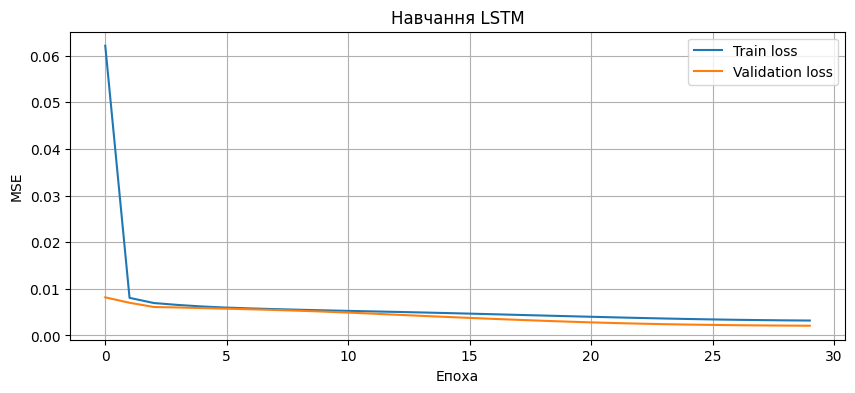

In [ ]:
# Навчіть LSTM-модель

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Навчання LSTM")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Виведіть структуру LSTM-моделі

model_lstm.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 25)             │         7,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,080 (211.25 KB)

 Trainable params: 18,026 (70.41 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 36,054 (140.84 KB)

In [ ]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування

# Рекурсивний прогноз на весь тестовий період
history_scaled = train_scaled.flatten().tolist()
lstm_predictions_scaled = []

for _ in range(len(test)):
    x_input = np.array(history_scaled[-window:]).reshape(1, window, 1)

    next_pred = model_lstm.predict(x_input, verbose=0)[0, 0]
    lstm_predictions_scaled.append(next_pred)

    # Додаємо прогноз до історії для наступного кроку
    history_scaled.append(next_pred)

# Повернення до початкового масштабу
lstm_pred_values = scaler.inverse_transform(
    np.array(lstm_predictions_scaled).reshape(-1, 1)
).flatten()

print("Кількість прогнозованих значень:", len(lstm_pred_values))


Кількість прогнозованих значень: 712


In [ ]:
# Сформуйте часові мітки для тестового прогнозу LSTM

lstm_pred = pd.Series(
    lstm_pred_values,
    index=test.index,
    name="LSTM"
)

display(lstm_pred.head())


,LSTM
DATE,
2022-12-20,22.438404
2022-12-21,22.455942
2022-12-22,22.418430
2022-12-23,22.337595
2022-12-24,22.226213


In [ ]:
# Обчисліть MAE, RMSE, MAPE для LSTM

from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = np.asarray(test, dtype=float)
y_pred = np.asarray(lstm_pred, dtype=float)

mae_lstm = mean_absolute_error(y_true, y_pred)
rmse_lstm = np.sqrt(mean_squared_error(y_true, y_pred))

mask = np.abs(y_true) > 1e-8
mape_lstm = np.mean(
    np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
) * 100

print(f"MAE:  {mae_lstm:.4f}")
print(f"RMSE: {rmse_lstm:.4f}")
print(f"MAPE: {mape_lstm:.2f}%")


MAE:  9.7294
RMSE: 11.1195
MAPE: 29.50%


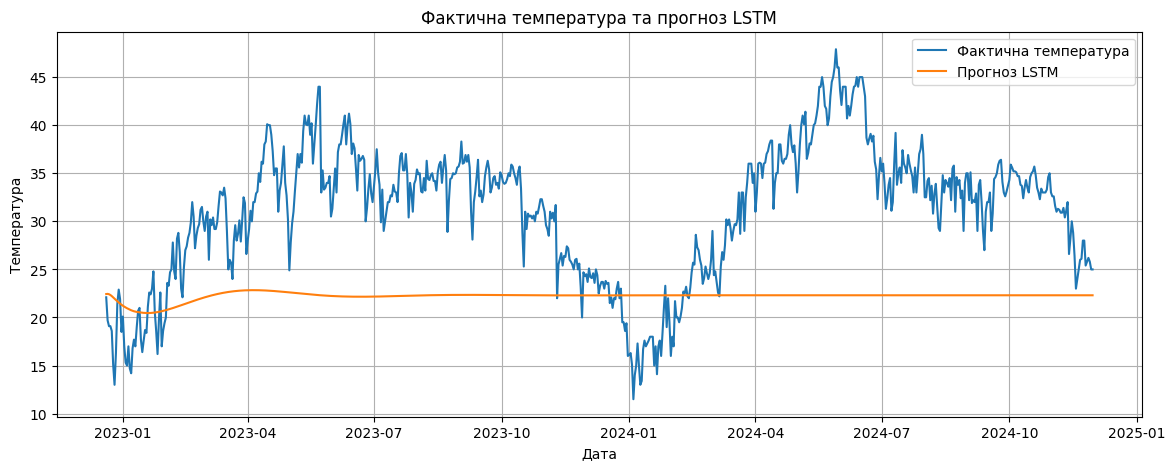

In [ ]:
# Візуалізуйте фактичні значення та прогноз LSTM

plt.figure(figsize=(14, 5))

plt.plot(test.index, test.values, label="Фактична температура")
plt.plot(lstm_pred.index, lstm_pred.values, label="Прогноз LSTM")

plt.title("Фактична температура та прогноз LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура")
plt.legend()
plt.grid(True)
plt.show()


Порівняння моделей

In [ ]:

# Створення підсумкової таблиці метрик
comparison = pd.DataFrame({
    "ARIMA": {
        "MAE": mean_absolute_error(test, arima_pred),
        "RMSE": np.sqrt(mean_squared_error(test, arima_pred)),
        "MAPE (%)": np.mean(
            np.abs((test.values[np.abs(test.values) > 1e-8] -
                    arima_pred.values[np.abs(test.values) > 1e-8]) /
                   test.values[np.abs(test.values) > 1e-8])
        ) * 100
    },
    "Prophet": {
        "MAE": mae_prophet,
        "RMSE": rmse_prophet,
        "MAPE (%)": mape_prophet
    },
    "LSTM": {
        "MAE": mae_lstm,
        "RMSE": rmse_lstm,
        "MAPE (%)": mape_lstm
    }
}).T

display(comparison.round(3))

# Порівняння за MAE
best_model = comparison["MAE"].idxmin()
print("Найкраща модель за MAE:", best_model)


,MAE,RMSE,MAPE (%)
ARIMA,9.750,11.125,29.690
Prophet,2.338,3.034,8.281
LSTM,9.729,11.119,29.500


Найкраща модель за MAE: Prophet


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У ході роботи було проаналізовано часовий ряд температури в Делі та виконано попередню обробку даних. Було побудовано графіки зміни температури, її розподілу та автокореляції. Для прогнозування використано три моделі: ARIMA, Prophet і LSTM. Якість прогнозів оцінено за метриками MAE, RMSE та MAPE. За результатами порівняння визначено модель, яка показала найкращу точність прогнозування на тестовій вибірці.